# Prediksi Perilaku Pembelian Pengunjung E-Commerce (Random Forest)

**Dataset**: UCI Online Shoppers Purchasing Intention
**Target**: `Revenue` (1 = membeli, 0 = tidak membeli)
**Model**: Random Forest dengan 100 pohon (n_estimators = 100)

## 1. Data Collection

Memuat data hasil preprocessing dari folder `data/processed/`. Random Forest tidak butuh scaling, jadi kita pakai `X_train.csv` dan `X_test.csv` (versi tanpa scaling).

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from config import RANDOM_STATE, OUTPUT_DIR
sns.set_style("whitegrid")

X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train = pd.read_csv("../data/processed/y_train.csv")["Revenue"]
y_test = pd.read_csv("../data/processed/y_test.csv")["Revenue"]

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("RANDOM_STATE:", RANDOM_STATE)

Train: (9864, 28)
Test: (2466, 28)
RANDOM_STATE: 42


#### Cek Proporsi Kelas Target

In [2]:
print("Distribusi target di data train:")
print(y_train.value_counts())
print(f"Persentase pembeli (train): {y_train.mean()*100:.2f}%")

print("\nDistribusi target di data test:")
print(y_test.value_counts())
print(f"Persentase pembeli (test): {y_test.mean()*100:.2f}%")

baseline = (y_test == 0).mean()
print(f"\nAccuracy jika selalu menebak 'tidak beli': {baseline*100:.2f}%")

Distribusi target di data train:
Revenue
0    8338
1    1526
Name: count, dtype: int64
Persentase pembeli (train): 15.47%

Distribusi target di data test:
Revenue
0    2084
1     382
Name: count, dtype: int64
Persentase pembeli (test): 15.49%

Accuracy jika selalu menebak 'tidak beli': 84.51%


## 2. Model Selection

Model yang dipakai adalah **Random Forest** dengan **100 pohon**.

Cara kerjanya: Random Forest membangun banyak decision tree. Tiap pohon dilatih dari sampel acak data latih, lalu prediksi akhir diambil dari suara terbanyak semua pohon. Karena pohon membelah data berdasarkan ambang batas (misalnya PageValues > 0,5) dan bukan menghitung jarak, skala fitur tidak berpengaruh.

In [3]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf_model.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih!")
print("Jumlah pohon:", len(rf_model.estimators_))

Model Random Forest berhasil dilatih!
Jumlah pohon: 100


## 3. Model Evaluation

### 3.1 Model Prediction

Melakukan prediksi terhadap data testing menggunakan model Random Forest yang telah dilatih.

In [4]:
# Melakukan prediksi
y_pred = rf_model.predict(X_test)

print("Prediksi berhasil dilakukan!")
print("Jumlah data yang diprediksi:", len(y_pred))

Prediksi berhasil dilakukan!
Jumlah data yang diprediksi: 2466


### 3.2 Metrik Evaluasi

Metrik yang dihitung: accuracy, precision, recall, dan F1-score. Kelas positif adalah 1 (pembeli).

In [5]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report
)

print("=== Random Forest (100 trees) ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

=== Random Forest (100 trees) ===
Accuracy : 0.8978
Precision: 0.7305
Recall   : 0.5393
F1-score : 0.6205

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.96      0.94      2084
           1       0.73      0.54      0.62       382

    accuracy                           0.90      2466
   macro avg       0.82      0.75      0.78      2466
weighted avg       0.89      0.90      0.89      2466



### 3.3 Confusion Matrix

Format confusion matrix di scikit-learn:
- Baris = Actual (sebenarnya)
- Kolom = Predicted (prediksi)

| | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | TN | FP |
| **Actual 1** | FN | TP |

TN = 2008 | FP = 76 | FN = 176 | TP = 206


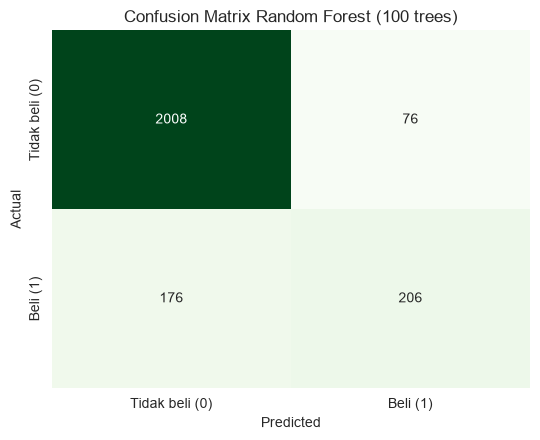

In [6]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=["Tidak beli (0)", "Beli (1)"],
            yticklabels=["Tidak beli (0)", "Beli (1)"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Random Forest (100 trees)")
plt.tight_layout()
plt.show()

Arti tiap kotak berdasarkan hasil Random Forest pada 2.466 data test:

| Kotak | Jumlah | Arti dalam kasus ini |
|---|---|---|
| **TN** (True Negative) | 2008 | Pengunjung yang tidak membeli dan model memprediksi tidak beli (benar) |
| **FP** (False Positive) | 76 | Pengunjung yang tidak membeli tapi model memprediksi beli (meleset) |
| **FN** (False Negative) | 176 | Pengunjung yang sebenarnya membeli tapi model memprediksi tidak beli (calon pembeli terlewat) |
| **TP** (True Positive) | 206 | Pengunjung yang membeli dan model memprediksi beli (benar) |

Pengecekan: TN + FP = 2084 pengunjung yang tidak membeli, dan TP + FN = 382 pengunjung yang membeli. Totalnya 2466, sama dengan jumlah data test.

**Hubungan dengan metrik:**
- Accuracy = (TP + TN) / total = (206 + 2008) / 2466 = **89,78%**
- Precision = TP / (TP + FP) = 206 / (206 + 76) = **73,05%**. Kalau model bilang "beli", tebakannya benar sekitar 73%.
- Recall = TP / (TP + FN) = 206 / (206 + 176) = **53,93%**. Dari 382 pembeli, model berhasil menemukan 206 orang.

**Interpretasi:**
- Model sangat baik mengenali pengunjung yang tidak membeli (2008 dari 2084 benar, sekitar 96%) dan hanya sedikit salah menandai non-pembeli sebagai pembeli (FP = 76).
- Kelemahannya ada di FN = 176: sekitar 46% calon pembeli tidak terdeteksi. Bagi perusahaan yang ingin menjaring sebanyak mungkin calon pembeli, FN adalah kerugian peluang penjualan, jadi angka ini yang paling perlu diperhatikan.
- Sebagai pembanding, KNN hanya menemukan 148 dari 382 pembeli (FN = 234). Random Forest menemukan lebih banyak pembeli (TP 206 vs 148).

### 3.4 Feature Importance

Random Forest bisa menunjukkan fitur mana yang paling berpengaruh dalam memprediksi pembelian. Nilainya dihitung dari seberapa besar tiap fitur membantu pohon-pohon memisahkan pembeli dan non-pembeli.

10 fitur terpenting:
PageValues                 0.3640
ExitRates                  0.0896
ProductRelated_Duration    0.0862
ProductRelated             0.0723
BounceRates                0.0568
Administrative_Duration    0.0561
Administrative             0.0437
Region                     0.0312
TrafficType                0.0305
Informational_Duration     0.0256
dtype: float64


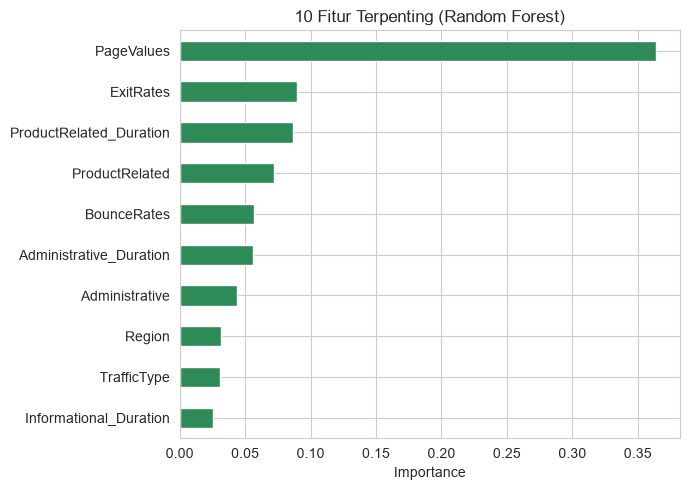

In [7]:
importance = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importance = importance.sort_values(ascending=False)

print("10 fitur terpenting:")
print(importance.head(10).round(4))

top10 = importance.head(10).sort_values()
plt.figure(figsize=(7, 5))
top10.plot(kind="barh", color="seagreen")
plt.xlabel("Importance")
plt.title("10 Fitur Terpenting (Random Forest)")
plt.tight_layout()
plt.show()

### 3.5 Random Forest Tanpa Scaling vs Dengan Scaling

Uji tambahan untuk melihat apakah Random Forest sensitif terhadap skala fitur.

In [8]:
def hitung_metrik(y_true, y_hat):
    return {
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precision": precision_score(y_true, y_hat, zero_division=0),
        "Recall": recall_score(y_true, y_hat, zero_division=0),
        "F1-score": f1_score(y_true, y_hat, zero_division=0),
    }

# RF dengan data yang sudah di-scale
X_train_scaled = pd.read_csv("../data/processed/X_train_scaled.csv")
X_test_scaled = pd.read_csv("../data/processed/X_test_scaled.csv")

rf_scaled = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = rf_scaled.predict(X_test_scaled)

perbandingan = pd.DataFrame({
    "RF tanpa scaling": hitung_metrik(y_test, y_pred),
    "RF dengan scaling": hitung_metrik(y_test, y_pred_scaled),
}).T.round(4)
perbandingan

,Accuracy,Precision,Recall,F1-score
RF tanpa scaling,0.8978,0.7305,0.5393,0.6205
RF dengan scaling,0.8982,0.7314,0.5419,0.6226


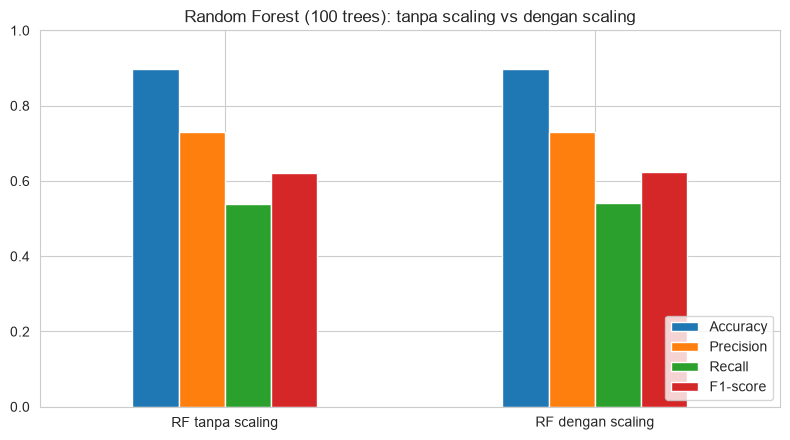

In [9]:
perbandingan.plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.title("Random Forest (100 trees): tanpa scaling vs dengan scaling")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/12_rf_scaling.png", dpi=150)
plt.show()

## 4. Menyimpan Model dan Hasil

Model Random Forest yang sudah dilatih disimpan ke file `rf_model.pkl` supaya bisa dipakai lagi tanpa latih ulang. Hasil evaluasinya (accuracy, precision, recall, F1-score, dan nilai TN, FP, FN, TP) disimpan ke `hasil_rf.json` agar bisa dibandingkan dengan hasil KNN.

In [10]:
import os, json, joblib
os.makedirs(OUTPUT_DIR, exist_ok=True)

joblib.dump(rf_model, f"{OUTPUT_DIR}/rf_model.pkl")

m = hitung_metrik(y_test, y_pred)
hasil_rf = {
    "model": "Random Forest (100 trees)",
    "accuracy": round(m["Accuracy"], 4),
    "precision": round(m["Precision"], 4),
    "recall": round(m["Recall"], 4),
    "f1": round(m["F1-score"], 4),
    "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
}
with open(f"{OUTPUT_DIR}/hasil_rf.json", "w") as f:
    json.dump(hasil_rf, f, indent=2)

hasil_rf

{'model': 'Random Forest (100 trees)',
 'accuracy': 0.8978,
 'precision': 0.7305,
 'recall': 0.5393,
 'f1': 0.6205,
 'TN': 2008,
 'FP': 76,
 'FN': 176,
 'TP': 206}

## 5. Inference Menggunakan Model yang Telah Dilatih

Memuat kembali model Random Forest dari file `rf_model.pkl`, lalu mencobanya pada 5 pengunjung pertama di data test.

In [11]:
# Load model dari file .pkl
model_rf_load = joblib.load(f"{OUTPUT_DIR}/rf_model.pkl")

# Ambil 5 pengunjung pertama dari data test (tanpa scaling, sesuai data latih RF)
sampel = X_test.head(5)
prediksi = model_rf_load.predict(sampel)

print("Prediksi untuk 5 pengunjung:")
for i, (pred, asli) in enumerate(zip(prediksi, y_test.head(5))):
    status_pred = "Beli" if pred == 1 else "Tidak beli"
    status_asli = "Beli" if asli == 1 else "Tidak beli"
    print(f"Pengunjung {i+1}: prediksi = {status_pred} | sebenarnya = {status_asli}")

Prediksi untuk 5 pengunjung:
Pengunjung 1: prediksi = Tidak beli | sebenarnya = Tidak beli
Pengunjung 2: prediksi = Tidak beli | sebenarnya = Tidak beli
Pengunjung 3: prediksi = Beli | sebenarnya = Beli
Pengunjung 4: prediksi = Tidak beli | sebenarnya = Tidak beli
Pengunjung 5: prediksi = Tidak beli | sebenarnya = Tidak beli


## Kesimpulan

Random Forest (100 trees) mendapat **accuracy 89,78%**, **precision 73,05%**, dan **recall 53,93%**. Dari 382 pembeli di data test, 206 berhasil ditemukan dan 176 terlewat.

Fitur terpenting adalah **PageValues**, jauh di atas fitur lain. Random Forest juga tidak terpengaruh scaling, berbeda dengan KNN.

Dibanding KNN (accuracy 87,19%, precision 64,35%, recall 38,74%), Random Forest lebih baik di semua metrik, terutama recall. Jadi untuk menjaring sebanyak mungkin calon pembeli, Random Forest lebih cocok, walaupun masih ada sekitar 46% calon pembeli yang terlewat.